# When crop prices rise, do tropical forests fall?

> **To write (Andrew):** a subtitle (one line) and a hook of 3-4 sentences for a general reader. Ideas: the 2024 cocoa price
> spike (the real cocoa price more than doubled); tropical forests lost every year (11 Mha per year in our 62 countries);
> the question of the article: do world crop prices drive deforestation? Say in one sentence what we find: prices do
> raise deforestation, but much less than the reference study suggests (about 16% of tree cover loss since 2001,
> 45 Mha, against 36% with their method); the effect works at the regional scale.

*Authors: Andrew Eberhardt, David ... | Data Science Project, 2026. Technical details are in the Appendix and in notebooks 3, 4 and 5.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("default")
plt.rcParams["figure.facecolor"] = "white"

# All data are read from GitHub. Switch BRANCH to "main" once the branch is merged.
BRANCH = "andrew-cleanup-berman"
BASE = f"https://raw.githubusercontent.com/AndrewEberhardt/DataScienceProject/{BRANCH}/data/"
RES = BASE + "processed/results/"           # results of notebook 4 (9 km models precomputed)

BERMAN_BETA = 1.27
SRC_FOREST = "Hansen et al. GFC v1.13"
SRC_GAEZ = "FAO/IIASA GAEZ v4"
SRC_PRICE = "World Bank Pink Sheet"
summary = pd.read_csv(RES + "summary.csv").set_index("model")
controls = pd.read_csv(RES + "controls_9km.csv")             # notebook 4, section 14: controls ladder
ident = pd.read_csv(RES + "identification_9km.csv")          # notebook 4, section 13: identification checks
size = pd.read_csv(RES + "effect_size_9km.csv")              # notebook 4, section 15: size of the effect
MAIN_SPEC = "Main: province x year + controls (step 4)"

## 1. A decade and a half of crop price shocks

> **To write (Andrew):** 2 short paragraphs. Points: prices of tropical crops are set on world markets; they moved a lot
> since 2000 (food crisis 2007-2008, commodity boom 2011, 2021-2022 spike, cocoa and coffee records in
> 2024-2025); a farmer at the forest edge sees these prices; read the figure below (which crop moved most).

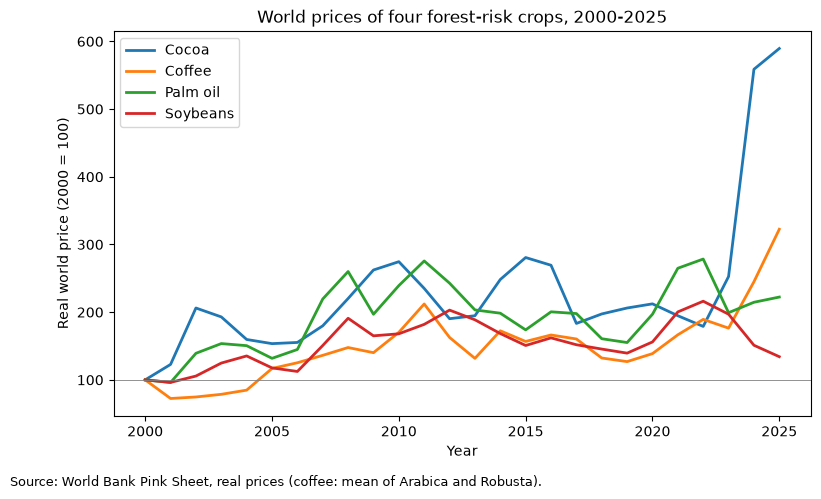

In [2]:
prices = pd.read_csv(BASE + "processed/commodity_prices_annual.csv")
SERIES = {"Cocoa": ["Cocoa"], "Coffee": ["Coffee, Arabica", "Coffee, Robusta"], "Palm oil": ["Palm oil"],
          "Soybeans": ["Soybeans"]}
P = pd.DataFrame({k: prices[prices.commodity.isin(v)].groupby("year").price_real.mean() for k, v in SERIES.items()})
P = (100 * P / P.loc[2000]).loc[2000:2025]

fig, ax = plt.subplots(figsize=(9, 5))
for crop in P:
    ax.plot(P.index, P[crop], lw=2, label=crop)
ax.axhline(100, color="grey", lw=0.6)
ax.set_xlabel("Year")
ax.set_ylabel("Real world price (2000 = 100)")
ax.set_title("World prices of four forest-risk crops, 2000-2025")
ax.legend()
fig.text(0.01, -0.03, f"Source: {SRC_PRICE}, real prices (coffee: mean of Arabica and Robusta).", fontsize=9)
plt.show()

## 2. What we already know

> **To write (Andrew):** a short literature review written as a story, not a list (course guideline: for each paper, what
> they did, how, what they found, what is missing; then what links the papers). Suggested thread:
> (1) Assuncao, Gandour and Rocha (2015): in the Brazilian Amazon, crop and cattle prices explain part of
> the deforestation of the 2000s, but policies explain the slowdown after 2004 (one country, municipalities);
> (2) Harding et al. (2021): commodity prices and the role of environmental regulation in Brazil (also one
> country); (3) Berman et al. (2023): the first study for the whole tropics, 0.5 degree cells, 2001-2018,
> shift-share price index, 35% of predicted forest loss due to prices; (4) Singh and Persson (2026, DeDuCE):
> which commodities replace the forest (cattle is the largest, so prices matter beyond crops).
> Gap and our contribution in 3 points: 6 times finer cells (9 km), 7 more years (2019-2025, including the
> cocoa and coffee records), and two new questions: at what spatial scale do prices act, and do protected
> areas dampen the effect? Add the full references in the Appendix.

## 3. Data: forests seen from space, crops from soil maps

> **To write (Andrew):** present the three data sources in plain words (table in Appendix A.1): Hansen satellite maps of
> forest loss (30 m pixels, 2001-2025), FAO GAEZ crop suitability (which crop can grow where), World Bank real
> crop prices. Then explain the idea of the price index without equations (formula in the Appendix). Points:
> world prices are the same everywhere, but a forest cell where cocoa grows well is exposed to the cocoa
> price, a cell where soybeans grow well to the soybean price; we weight each crop by how suitable the cell
> is (FAO GAEZ data); we use 511,427 cells of 9 km in 62 tropical countries, 6 times finer than Berman et al.
> (55 km); we compare cells of the same country in the same year, so national policies and crises cancel out.
> Comment the maps: cocoa and oil palm in humid forests (Amazon, Congo, Southeast Asia), soybeans at the
> edges (southern Brazil, India, Australia).

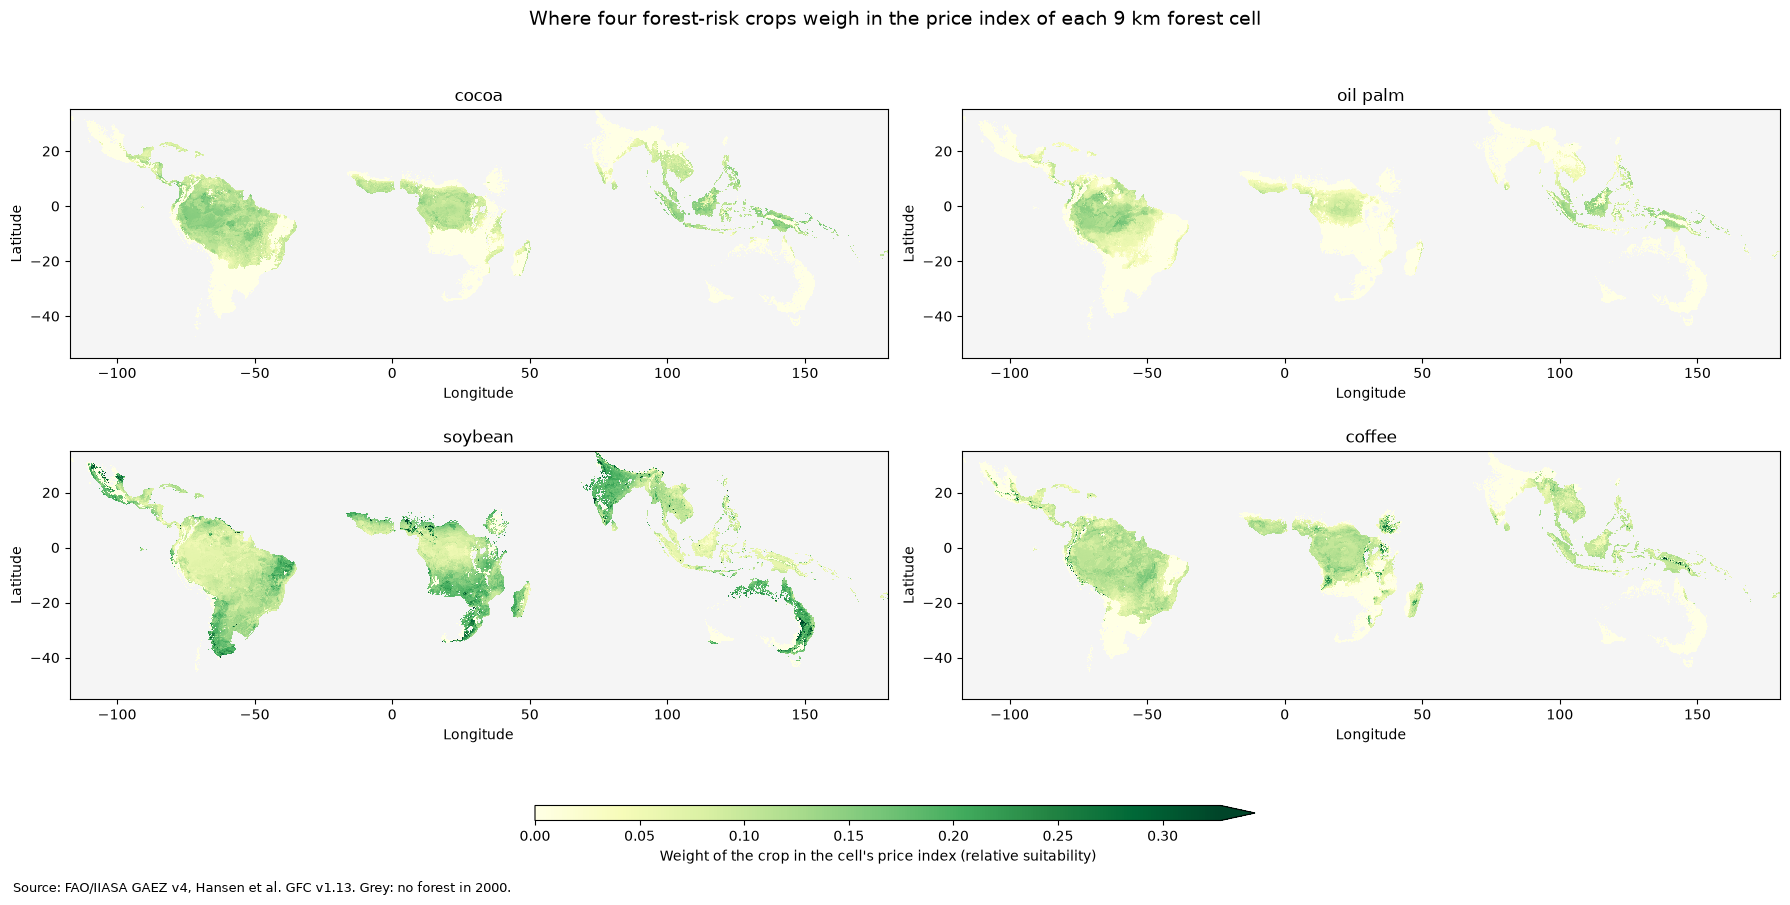

In [3]:
CROPS = ["banana", "cocoa", "coconut", "coffee", "cotton", "maize", "oil palm", "rice", "soybean",
         "sugarcane", "tea", "tobacco", "wheat"]                  # the 13 crops of the main index
cells = pd.read_csv(BASE + "processed/grid_cells.csv.gz", usecols=["cell_id", "row", "col"])
suit = pd.read_csv(BASE + "processed/grid_suitability.csv.gz")
suit.columns = ["cell_id"] + CROPS + ["barley", "sorghum"]
S = cells[["cell_id"]].merge(suit, on="cell_id", how="left")[CROPS].to_numpy(float)
tot = S.sum(axis=1, keepdims=True)
alpha = pd.DataFrame(np.divide(S, tot, out=np.full_like(S, np.nan), where=tot > 0), columns=CROPS)

r0, r1, c0, c1 = cells.row.min(), cells.row.max() + 1, cells.col.min(), cells.col.max() + 1
extent = [-180 + c0 / 12, -180 + c1 / 12, 90 - r1 / 12, 90 - r0 / 12]
vmax = np.nanpercentile(alpha.to_numpy(), 99)

fig, axes = plt.subplots(2, 2, figsize=(18, 9))
for ax, crop in zip(axes.flat, ["cocoa", "oil palm", "soybean", "coffee"]):
    g = np.full((r1 - r0, c1 - c0), np.nan)
    g[cells.row - r0, cells.col - c0] = alpha[crop]
    im = ax.imshow(g, extent=extent, cmap="YlGn", vmin=0, vmax=vmax, interpolation="nearest")
    ax.set_facecolor("whitesmoke")
    ax.set_title(crop)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
fig.suptitle("Where four forest-risk crops weigh in the price index of each 9 km forest cell", fontsize=14)
b = 1.1 / 9
fig.tight_layout(rect=(0, b, 1, 1))
cax = fig.add_axes([0.3, 0.65 * b, 0.4, 0.15 / 9])
fig.colorbar(im, cax=cax, orientation="horizontal", extend="max",
             label="Weight of the crop in the cell's price index (relative suitability)")
fig.text(0.01, 0.0, f"Source: {SRC_GAEZ}, {SRC_FOREST}. Grey: no forest in 2000.", fontsize=9)
plt.show()

### Where the data can mislead

> **To write (Andrew):** one short paragraph per bias (course element 3: data sources and possible biases). Points:
> (1) Hansen "forest loss" is tree cover loss: it also counts harvested plantations (oil palm, timber) and
> fires, not only clearing of natural forest; we use canopy above 25% and check 50% (result unchanged, 0.95);
> (2) GAEZ gives potential suitability, not the crops actually planted, so the index measures exposure to
> prices, not real income (this is why the index is clean: it does not depend on farmers' choices);
> (3) world prices are not farm-gate prices: exchange rates, taxes and marketing boards (cocoa in Cote
> d'Ivoire and Ghana) sit in between; the country x year fixed effects absorb what is common to a country;
> (4) the sample: 62 tropical countries, 9 km cells with forest in 2000; the WDPA has missing or wrong
> creation years for some protected areas.

## 4. Can we call it causal?

> **To write (Andrew):** the identification argument for a reader with a statistics background (course element 2, the
> largest part of the grade). Points, one paragraph each:
> (1) the naive comparison fails: places with more deforestation differ in roads, population, policies;
> (2) the design of Berman et al.: same cell over time (cell fixed effect), only cells of the same country in the same
> year (country x year fixed effect); what is left is how world prices of the crops a cell can grow change from year
> to year; a shift-share or Bartik design, a diff-in-diff with a continuous treatment, not an event study;
> (3) the problem we found: in this design, the price index of two years ahead predicts today's deforestation as well
> as today's index (0.98 vs 1.04, notebook 4 section 13): exposed cells were on different paths (deforestation
> fronts moving while crop prices rose), so the design mixes the price effect with regional trends;
> (4) our answer: controls for characteristics of 2000 x year (forest cover deciles, protected share, cattle density,
> average suitability) and province x year fixed effects, our main model; cell-specific trends as a lower bound;
> nothing measured after 2000 (bad controls); show the ladder figure (the effect falls from 0.99 to 0.37, then 0.12);
> (5) other checks: first differences (0.22), leave one crop out (0.75 to 1.17), large producers dropped, permutation
> test; price shocks only (detrended index) unstable across periods, kept as a check;
> (6) what remains an assumption: within a province and a year, after the controls, the crop mix of a cell is not
> linked to other shocks that move with crop prices.

In [4]:
# Live estimation on 0.5 degree cells (2001-2025, 13 crops). The 9 km models use 12 million cell-years and
# are estimated in notebook 4; here we rerun the 0.5 degree model, which takes a few seconds.
import warnings
import pyfixest as pf
import rasterio

GAEZ_CODES = {"banana": ["ban"], "cocoa": ["coc"], "coconut": ["con"], "coffee": ["cof"], "cotton": ["cot"],
              "maize": ["mze"], "oil palm": ["olp"], "rice": ["rcd", "rcw"], "soybean": ["soy"],
              "sugarcane": ["suc"], "tea": ["tea"], "tobacco": ["tob"], "wheat": ["whe"]}
PRICE_SERIES = {"banana": ["Banana, US"], "cocoa": ["Cocoa"], "coconut": ["Coconut oil"],
                "coffee": ["Coffee, Arabica", "Coffee, Robusta"], "cotton": ["Cotton, A Index"], "maize": ["Maize"],
                "oil palm": ["Palm oil"], "rice": ["Rice, Thai 5%"], "soybean": ["Soybeans"],
                "sugarcane": ["Sugar, world"], "tea": ["Tea, avg 3 auctions"], "tobacco": ["Tobacco, US import u.v."],
                "wheat": ["Wheat, US HRW"]}
YEARS = list(range(2001, 2026))

# Forest loss summed over 0.5 degree blocks (6 x 6 cells of 9 km), country = the one with most forest
grid = pd.read_csv(BASE + "processed/grid_cells.csv.gz")
grid["block"] = (grid.row // 6) * 720 + grid.col // 6
blocks = grid.groupby("block")[[f"loss25_{y}" for y in YEARS]].sum().reset_index()
country = (grid.groupby(["block", "iso3"]).forest25_px.sum().reset_index().sort_values("forest25_px")
           .drop_duplicates("block", keep="last")[["block", "iso3"]])
blocks = blocks.merge(country, on="block")
blocks = blocks[(90 - ((blocks.block // 720) * 6 + 3) / 12).abs() <= 23.44].reset_index(drop=True)   # tropics

# Mean GAEZ suitability of each block (rice: best of dryland and wetland rice)
for crop, codes in GAEZ_CODES.items():
    layers = []
    for c in codes:
        with rasterio.open(BASE + f"raw/gaez/sxHr_{c}.tif") as src:
            layers.append(src.read(1).astype(np.float32))
    a = np.max(layers, axis=0)
    a[a < 0] = np.nan                                       # water / no data
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)     # blocks entirely at sea
        blocks[crop] = np.nanmean(a.reshape(360, 6, 720, 6), axis=(1, 3)).ravel()[blocks.block]

# Price index: world prices weighted by relative suitability, in logs
P = pd.DataFrame({c: prices[prices.commodity.isin(s)].groupby("year").price_real.mean() for c, s in PRICE_SERIES.items()})
P = 100 * P / P.loc[2000]
S = blocks[list(PRICE_SERIES)].to_numpy(float)
tot = S.sum(axis=1, keepdims=True)
weights = np.divide(S, tot, out=np.full_like(S, np.nan), where=tot > 0)
lnP = np.log(weights @ P.loc[YEARS, list(PRICE_SERIES)].to_numpy().T)          # blocks x years

panel = pd.DataFrame({"block": np.repeat(blocks.block, len(YEARS)), "iso3": np.repeat(blocks.iso3, len(YEARS)),
                      "year": np.tile(YEARS, len(blocks)), "lnP": lnP.ravel(),
                      "y": np.arcsinh(blocks[[f"loss25_{y}" for y in YEARS]].to_numpy().ravel())}).dropna()
fit = pf.feols("y ~ lnP | block + iso3:year", panel, vcov={"CRV1": "block"})
print(f"{len(blocks):,} blocks of 0.5 degree, {fit._N:,} block-years; effect of lnP: "
      f"{fit.coef().iloc[0]:.2f} (SE {fit.se().iloc[0]:.2f}), same as notebook 4: "
      f"{summary.loc['0.5 deg, 2001-2025, 13 crops', 'Estimate']:.2f}")

13,753 blocks of 0.5 degree, 333,075 block-years; effect of lnP: 1.66 (SE 0.06), same as notebook 4: 1.66


In [5]:
# Reverse causality: drop the countries that produce a large share of world output of one of the 13 crops
# (FAOSTAT, mean 1999-2001, before our period)
share = pd.read_csv(BASE + "processed/world_production_share.csv")
top = share.loc[share.groupby("iso3").share_world_production.idxmax()].set_index("iso3")
large = {}
for thr in (0.10, 0.05):
    drop = top.index[top.share_world_production >= thr]
    f = pf.feols("y ~ lnP | block + iso3:year", panel[~panel.iso3.isin(drop)], vcov={"CRV1": "block"})
    large[thr] = (f.coef().iloc[0], f.se().iloc[0])
    print(f"Without the {len(drop)} countries above {thr:.0%} of world production of one crop: "
          f"{f.coef().iloc[0]:.2f} (SE {f.se().iloc[0]:.2f})")
    print("   dropped:", ", ".join(f"{i} ({top.crop[i]} {top.share_world_production[i]:.0%})" for i in drop))

Without the 9 countries above 10% of world production of one crop: 1.50 (SE 0.07)
   dropped: ARG (soybean 14%), BRA (sugarcane 26%), CIV (cocoa 40%), GHA (cocoa 13%), IDN (oil palm 30%), IND (tea 28%), MYS (oil palm 47%), PHL (coconut 25%), VNM (coffee 10%)


Without the 15 countries above 5% of world production of one crop: 1.36 (SE 0.07)
   dropped: ARG (soybean 14%), BGD (rice 6%), BRA (sugarcane 26%), CIV (cocoa 40%), COL (coffee 8%), ECU (banana 9%), GHA (cocoa 13%), IDN (oil palm 30%), IND (tea 28%), KEN (tea 9%), LKA (tea 10%), MYS (oil palm 47%), NGA (cocoa 9%), PHL (coconut 25%), VNM (coffee 10%)


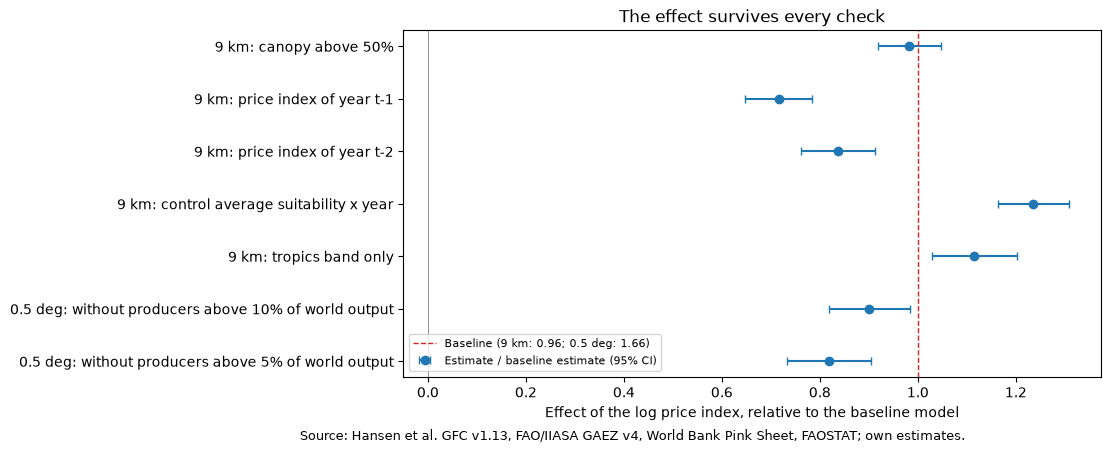

In [6]:
# All robustness checks in one figure: each estimate relative to its own baseline (= 1)
main9 = summary.loc["MAIN: 9 km, 2001-2025, 13 crops"]
base05 = fit.coef().iloc[0]
rows = [("9 km: canopy above 50%", "Canopy 50%"), ("9 km: price index of year t-1", "Price index t-1"),
        ("9 km: price index of year t-2", "Price index t-2"), ("9 km: control average suitability x year",
        "Average suitability x year"), ("9 km: tropics band only", "Tropics band only")]
r = pd.DataFrame([(lab, summary.loc[m, "Estimate"] / main9.Estimate, summary.loc[m, "Std. Error"] / main9.Estimate)
                  for lab, m in rows] +
                 [(f"0.5 deg: without producers above {thr:.0%} of world output", b / base05, se / base05)
                  for thr, (b, se) in large.items()], columns=["check", "ratio", "se"])
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(r))[::-1]
ax.errorbar(r.ratio, y, xerr=1.96 * r.se, fmt="o", capsize=3, label="Estimate / baseline estimate (95% CI)")
ax.axvline(1, color="tab:red", ls="--", lw=1, label="Baseline (9 km: 0.96; 0.5 deg: 1.66)")
ax.axvline(0, color="grey", lw=0.6)
ax.set_yticks(y)
ax.set_yticklabels(r.check)
ax.set_xlim(left=-0.05)
ax.set_xlabel("Effect of the log price index, relative to the baseline model")
ax.set_title("Robustness checks of the Berman design (country x year fixed effects)")
ax.legend(fontsize=8, loc="lower left")
fig.text(0.01, -0.03, f"Source: {SRC_FOREST}, {SRC_GAEZ}, {SRC_PRICE}, FAOSTAT; own estimates.", fontsize=9)
plt.show()

In [ ]:
# Adding controls one step at a time (notebook 4, section 14), and the leads test (section 13)
lad = controls[controls.check.isin(["price index", "detrended index"])]
steps = lad.model.unique()
fig, ax = plt.subplots(figsize=(9, 4.5))
for k, (label, g) in enumerate(lad.groupby("check", sort=False)):
    y = np.arange(len(g))[::-1] + (0.15 if k == 0 else -0.15)
    ax.errorbar(g.Estimate, y, xerr=1.96 * g["Std. Error"], fmt="o", capsize=3,
                label="World price index" if label == "price index" else "Detrended index (price shocks only)")
ax.axvline(0, color="grey", lw=0.6)
ax.set_yticks(np.arange(len(steps))[::-1])
ax.set_yticklabels(steps)
ax.set_xlabel("Effect of the log crop price index on asinh(deforested pixels), 95% CI")
ax.set_title("Controls for regional trends divide the effect by 3 (9 km cells, 2001-2025)")
ax.legend(fontsize=8)
fig.text(0.01, -0.03, f"Source: {SRC_FOREST}, {SRC_GAEZ}, {SRC_PRICE}, WDPA, AGLW, GADM; own estimates.", fontsize=9)
plt.show()

leads = ident[ident.check == "leads"].iloc[1:]           # model with the index of t, t+1 and t+2
print("Berman design, index of year t, t+1 and t+2 (2001-2023):",
      ", ".join(f"{t}: {e:.2f} (SE {s:.2f})" for t, e, s in zip(leads.term, leads.Estimate, leads["Std. Error"])))
fd = ident[ident.model == "9 km: first differences"].iloc[0]
print(f"First differences: {fd.Estimate:.2f} (SE {fd['Std. Error']:.2f})")
loo = ident[ident.check == "leave one crop out"]
print(f"Leave one crop out: from {loo.Estimate.min():.2f} to {loo.Estimate.max():.2f}")

## 5. Higher prices, more deforestation

> **To write (Andrew):** the main result in plain words, with the main model (province x year fixed effects and controls
> of 2000, notebook 4 sections 14-15). Numbers to cite: beta 0.37 (lower bound 0.12 with cell trends); a typical price
> shock raises deforestation by about 1.2% the same year; if all crop prices rise by 10%, about 0.4 Mha more forest is
> lost each year; price changes since 2001 explain about 16% of tree cover loss over 2001-2025 (45 Mha, 95% CI 13-19%;
> lower bound 5%), against 36% with the Berman design on the same data (Berman et al.: 35% over 2001-2018); the 2024
> cocoa spike (+121%) added about 3% to deforestation that year (0.7 Mha), spread over all humid forests because GAEZ
> suitability spreads cocoa everywhere. Say clearly that the effect is real but about a third of what the reference
> design gives.

In [7]:
main = "MAIN: 9 km, 2001-2025, 13 crops"          # Berman design at 9 km (notebook 4)
inference = pd.read_csv(RES + "inference.csv").set_index("model")
est = size[size.bound == "estimate"].set_index("spec")
lo, hi = size[size.bound == "low"].set_index("spec"), size[size.bound == "high"].set_index("spec")
berman = "Berman design (step 1)"
m = est.loc[MAIN_SPEC]
print(f"Main model (province x year fixed effects + controls of 2000): beta {m.beta:.2f} "
      f"(95% CI {lo.loc[MAIN_SPEC, 'beta']:.2f} to {hi.loc[MAIN_SPEC, 'beta']:.2f}); "
      f"lower bound with cell trends {est.loc['Lower bound: + cell trends (step 5)', 'beta']:.2f}")
print(f"A typical price shock ({m.sd_log_index:.3f} log points) raises deforestation by {m.typical_shock_pct:.1f}%")
print(f"All crop prices +10%: {m.ha_per_year_10pct / 1e6:.2f} Mha more tree cover loss per year")
print(f"Share of tree cover loss 2001-2025 due to price changes: {m.share_due_to_prices:.0%} ({m.mha_due_to_prices:.0f} Mha, "
      f"95% CI {lo.loc[MAIN_SPEC, 'share_due_to_prices']:.0%} to {hi.loc[MAIN_SPEC, 'share_due_to_prices']:.0%}); "
      f"Berman design: {est.loc[berman, 'share_due_to_prices']:.0%}")
print(f"2024 cocoa spike: +{m.cocoa_2024_pct:.1f}% deforestation in 2024 ({m.cocoa_2024_extra_ha / 1e6:.2f} Mha)")
print(f"Berman design: beta {est.loc[berman, 'beta']:.2f}, permutation p-value "
      f"{inference.loc[main, 'permutation p']:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(est))[::-1]
ax.errorbar(100 * est.share_due_to_prices, y, fmt="o", capsize=4,
            xerr=[100 * (est.share_due_to_prices - lo.share_due_to_prices), 100 * (hi.share_due_to_prices - est.share_due_to_prices)])
ax.axvline(35, color="tab:red", ls="--", lw=1, label="Berman et al. (2023): 35% (2001-2018)")
ax.set_yticks(y)
ax.set_yticklabels(est.index)
ax.set_xlim(0, 45)
ax.set_xlabel("Share of tree cover loss 2001-2025 due to crop price changes (%), 95% CI")
ax.set_title("How much deforestation do crop prices explain?")
ax.legend(fontsize=8, loc="lower right")
fig.text(0.01, -0.03, f"Source: {SRC_FOREST}, {SRC_GAEZ}, {SRC_PRICE}; own estimates.", fontsize=9)
plt.show()

Main coefficient: 0.96 (95% CI 0.90 to 1.03), extra effect after 2018: +0.31
Share of predicted deforestation due to price changes since 2001: 44%
Permutation p-value: 0.006


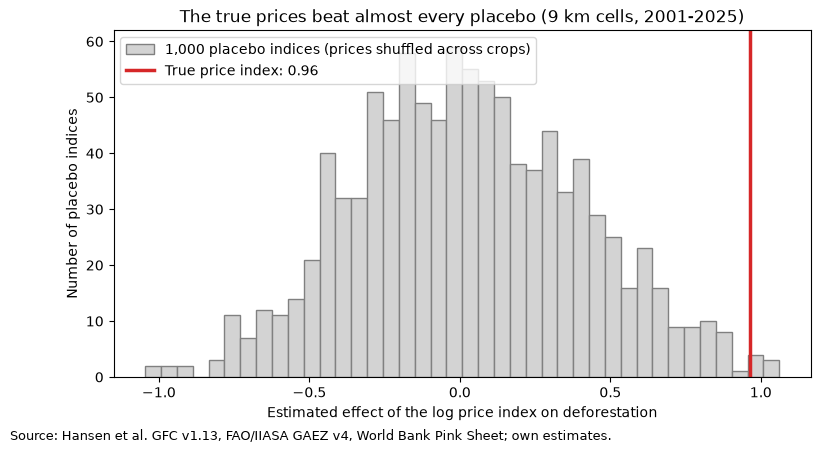

In [8]:
perm = pd.read_csv(RES + "permutation_9km.csv")[main]
b0, draws = perm.iloc[0], perm.iloc[1:]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(draws, bins=40, color="lightgrey", edgecolor="grey", label="1,000 placebo indices (prices shuffled across crops)")
ax.axvline(b0, color="tab:red", lw=2.5, label=f"True price index: {b0:.2f}")
ax.set_xlabel("Estimated effect of the log price index on deforestation")
ax.set_ylabel("Number of placebo indices")
ax.set_title("Permutation test, Berman design: true prices beat almost every placebo (9 km, 2001-2025)")
ax.legend()
fig.text(0.01, -0.03, f"Source: {SRC_FOREST}, {SRC_GAEZ}, {SRC_PRICE}; own estimates.", fontsize=9)
plt.show()

## 6. Checking the original study

> **To write (Andrew):** what replicating means and what we found. Points: on Berman et al.'s own 55 km cells and period we
> find 1.97 instead of their 1.27; with their own files we get exactly 1.27; the forest data are identical
> (their outcome or ours gives the same result); the whole gap comes from the price index (two price series,
> banana and sugar, and an older version of the FAO data). Lesson for the reader: the sign and significance
> are solid, the exact size depends on choices that papers rarely discuss.

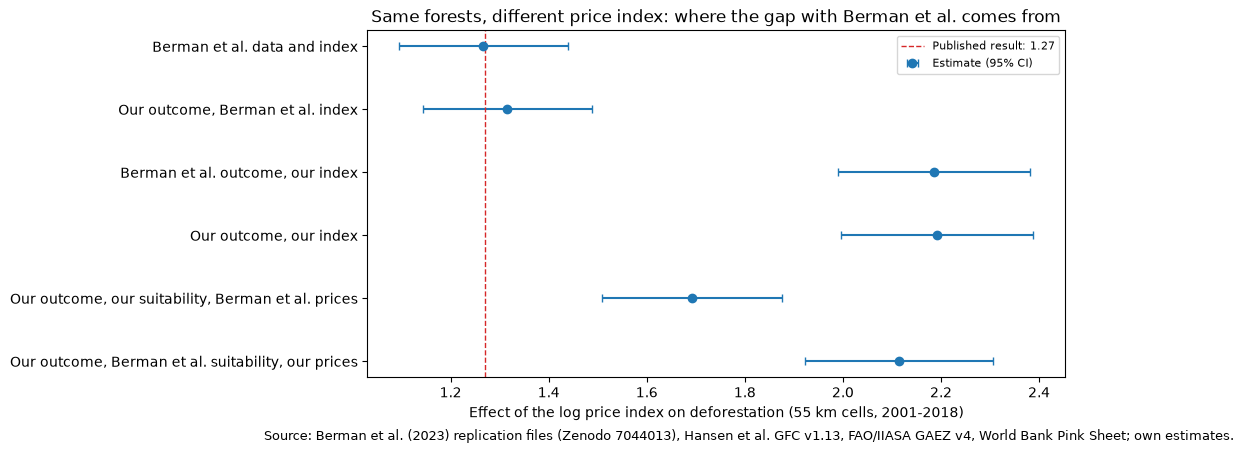

In [9]:
comp = pd.read_csv(BASE + "processed/berman_comparison.csv")
keep = ["Berman et al. data and index", "Our outcome, Berman et al. index", "Berman et al. outcome, our index",
        "Our outcome, our index", "Our outcome, our suitability, Berman et al. prices",
        "Our outcome, Berman et al. suitability, our prices"]
r = comp.set_index("model").loc[keep[::-1]]
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(r))
ax.errorbar(r.beta, y, xerr=1.96 * r.se, fmt="o", capsize=3, label="Estimate (95% CI)")
ax.axvline(BERMAN_BETA, color="tab:red", ls="--", lw=1, label="Published result: 1.27")
ax.set_yticks(y)
ax.set_yticklabels(r.index)
ax.set_xlabel("Effect of the log price index on deforestation (55 km cells, 2001-2018)")
ax.set_title("Same forests, different price index: where the gap with Berman et al. comes from")
ax.legend(loc="upper right", fontsize=8)
fig.text(0.01, -0.03, f"Source: Berman et al. (2023) replication files (Zenodo 7044013), {SRC_FOREST}, "
         f"{SRC_GAEZ}, {SRC_PRICE}; own estimates.", fontsize=9)
plt.show()

## 7. The price that matters is the region's, not the plot's

> **To write (Andrew):** the neighbour result. Points: we add the price index of the land around each cell, in rings up to
> 110 km; the effect moves to the ring at 60-110 km and the cell's own effect falls from 0.97 to about 0.16;
> interpretation: deforestation responds to the crop mix of the whole region (roads, mills, labour, traders),
> or the suitability of a single 9 km cell is a noisy measure; consequence: finer maps do not capture the
> mechanism better, and policies must think at the regional scale.

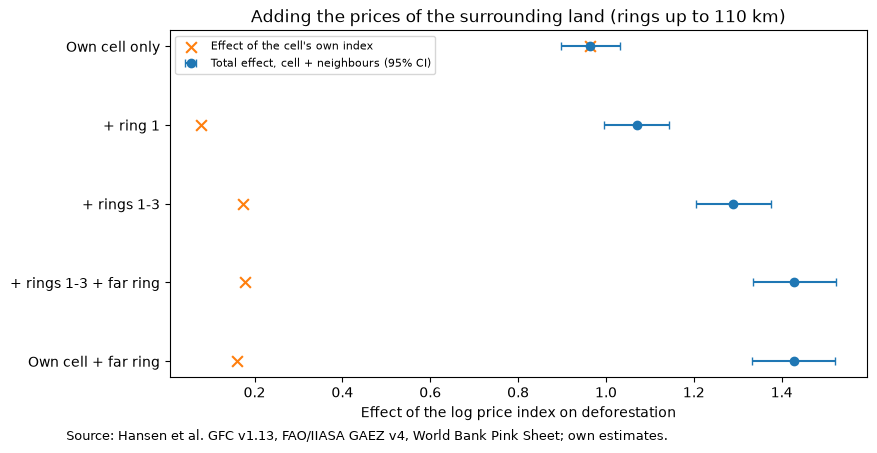

In [10]:
nb = pd.read_csv(RES + "neighbours.csv").set_index("model")
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(nb))[::-1]
ax.errorbar(nb.total, y, xerr=1.96 * nb["total SE"], fmt="o", capsize=3, label="Total effect, cell + neighbours (95% CI)")
ax.scatter(nb["lnP (beta)"], y, marker="x", s=60, color="tab:orange", label="Effect of the cell's own index")
ax.set_yticks(y)
ax.set_yticklabels(nb.index)
ax.set_xlabel("Effect of the log price index on deforestation")
ax.set_title("Adding the prices of the surrounding land (rings up to 110 km)")
ax.legend(fontsize=8, loc="upper left")
fig.text(0.01, -0.03, f"Source: {SRC_FOREST}, {SRC_GAEZ}, {SRC_PRICE}; own estimates.", fontsize=9)
plt.show()

## 8. Can protection stop it?

> **To write (Andrew):** the protected areas result and its limit. Points: protected forest cells lost 7.3% of their forest
> over 2001-2025, the others 14.2%; comparing cells with the same forest cover, a fully protected cell
> responds about 30% less to prices, and about 65% less under strict protection (IUCN I-IV); but areas
> protected after 2000 were created where pressure was already high (+0.26): the location of parks is not
> random, so this is a strong correlation, not proof that parks cause the difference.

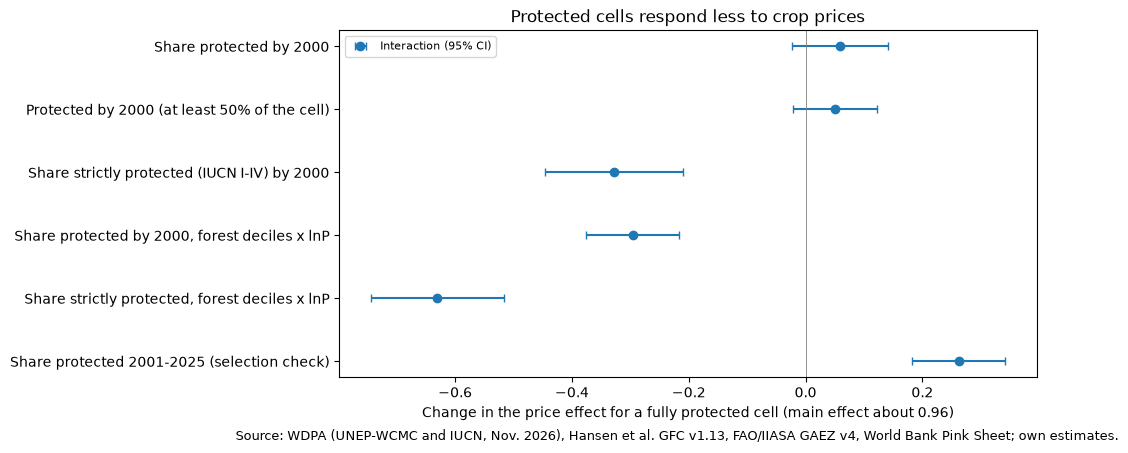

In [11]:
pa = pd.read_csv(RES + "protected_areas.csv")
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(pa))[::-1]
ax.errorbar(pa.Estimate, y, xerr=1.96 * pa["Std. Error"], fmt="o", capsize=3, label="Interaction (95% CI)")
ax.axvline(0, color="grey", lw=0.6)
ax.set_yticks(y)
ax.set_yticklabels(pa.model)
ax.set_xlabel("Change in the price effect for a fully protected cell (main effect about 0.96)")
ax.set_title("Protected cells respond less to crop prices")
ax.legend(fontsize=8)
fig.text(0.01, -0.03, f"Source: WDPA (UNEP-WCMC and IUCN, Nov. 2026), {SRC_FOREST}, {SRC_GAEZ}, "
         f"{SRC_PRICE}; own estimates.", fontsize=9)
plt.show()

## 9. Why beef is not in the index

> **To write (Andrew):** short section from notebook 5 (about 200 words). Points, in this order:
> (1) cattle is the first driver: in DeDuCE, pasture for cattle replaced 46.9 Mha of forest in our 62 countries over
> 2001-2023, two thirds of it in Brazil (31.9 Mha); (2) Berman et al. only add meat to their index in an appendix
> (1.27 becomes 1.54) and never estimate a beef effect on its own; (3) we test it directly: world beef price x cattle
> density in 2000 (AGLW maps), same 9 km model as the crops; (4) result: a stable negative effect (-0.26), but it
> disappears (-0.03, 95% CI about -0.25 to +0.19) once cattle areas get their own trend; the beef price doubled over
> the period while deforestation moved away from old cattle areas to new frontiers, and with one price series the two
> cannot be separated (figure); (5) at the country level nothing either: no link with the export share, and local
> producer prices are missing where cattle matters (David: 0 of 21 countries where the local price follows the world
> price); (6) conclusion: world prices cannot identify the beef effect, which is why the index keeps the 13 crops and
> why cattle is our main limit (section 10). Details: Appendix A.5 and notebook 5.

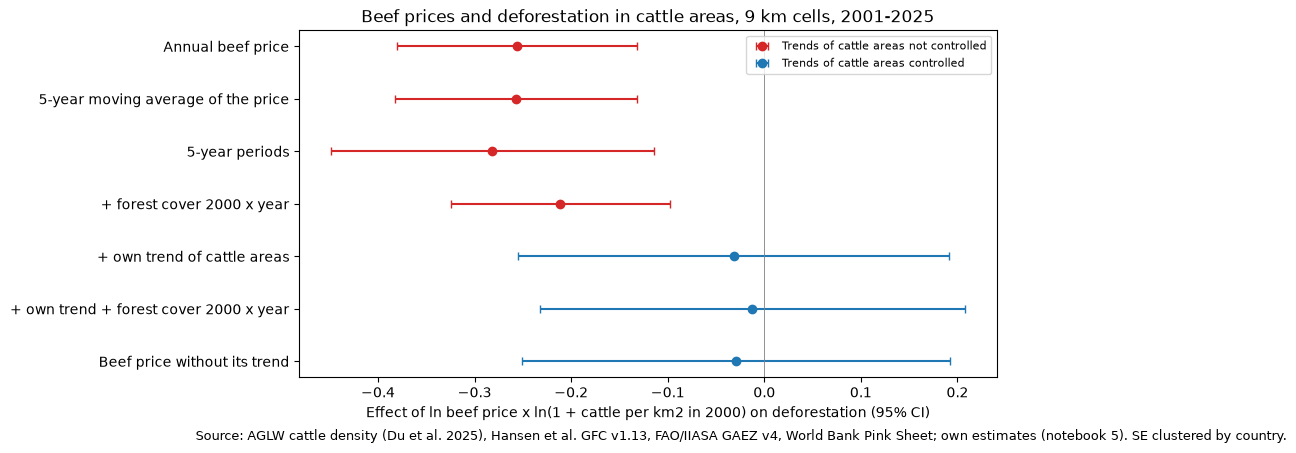

In [12]:
beef = pd.read_csv(RES + "beef_grid_9km.csv")
beef = beef[beef.term.str.startswith("beef") & ~beef.model.str.contains("region")].set_index("model")
rows = {  # model in notebook 5: (label, trend controlled)
    "1 Annual beef price": ("Annual beef price", False),
    "3 5-year moving average": ("5-year moving average of the price", False),
    "10 5-year periods (long differences)": ("5-year periods", False),
    "4 + forest 2000 x year": ("+ forest cover 2000 x year", False),
    "5 + cattle x trend": ("+ own trend of cattle areas", True),
    "6 + cattle x trend + forest 2000 x year": ("+ own trend + forest cover 2000 x year", True),
    "7 Beef price without its trend": ("Beef price without its trend", True),
}
b = beef.loc[list(rows)]
trend = np.array([v[1] for v in rows.values()])
y = np.arange(len(b))[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
for flag, color, label in [(False, "tab:red", "Trends of cattle areas not controlled"),
                           (True, "tab:blue", "Trends of cattle areas controlled")]:
    m = trend == flag
    ax.errorbar(b.Estimate[m], y[m], xerr=1.96 * b["SE country"][m], fmt="o", capsize=3, color=color, label=label)
ax.axvline(0, color="grey", lw=0.6)
ax.set_yticks(y)
ax.set_yticklabels([v[0] for v in rows.values()])
ax.set_xlabel("Effect of ln beef price x ln(1 + cattle per km2 in 2000) on deforestation (95% CI)")
ax.set_title("Beef prices and deforestation in cattle areas, 9 km cells, 2001-2025")
ax.legend(fontsize=8, loc="upper right")
fig.text(0.01, -0.03, f"Source: AGLW cattle density (Du et al. 2025), {SRC_FOREST}, {SRC_GAEZ}, {SRC_PRICE}; "
         "own estimates (notebook 5). SE clustered by country.", fontsize=9)
plt.show()

## 10. Limits and extensions

> **To write (Andrew):** a critical discussion (course element 5). Limits, one sentence each: (1) the size of the effect
> depends on the controls (0.99 to 0.12) and on how the index is built (1.27 vs 1.97 on the same forests, section 6);
> only the sign is robust; (2) the leads test: in the Berman design future prices predict today's deforestation;
> controls fix most of it, but we cannot rule out all trends; (3) price shocks alone (detrended index) give an
> unstable effect across periods; (4) GAEZ suitability is potential, not actual: it spreads cocoa or oil palm over all
> humid forests; (5) sections 7 and 8 (spatial scale, protected areas) use the Berman design, and the protected areas
> result is a correlation; (6) cattle, the first driver, is not in the index (section 9), timber neither; (7) tree
> cover loss is not only deforestation (fires: 2024 in Brazil and Bolivia).
> Extensions: farm-gate prices instead of world prices, actual crop maps instead of suitability, cattle in Brazil
> with local prices and municipal data (as Assuncao et al. 2015), an event study for protected areas using their
> creation dates, the role of roads and mills to explain the regional scale.

## 11. What this means

> **To write (Andrew):** conclusion of 2 paragraphs. Points: what we learned (prices matter, but less than the
> reference study suggests: about 16% of tree cover loss, 45 Mha; the effect works at the regional scale; checking a
> published design with leads and controls changes its size by a factor of 3); one sentence for policy (price booms
> are warning signals, but most deforestation comes from other drivers, so price-based policies alone will not stop
> it).

In [13]:
# Word count of the article (markdown cells before the Appendix; the limit is 3,000 words)
import json, re
nbk = json.load(open("6-Article.ipynb"))
words = 0
for c in nbk["cells"]:
    s = "".join(c["source"])
    if s.startswith("# Appendix"):
        break
    if c["cell_type"] == "markdown" and "To write (Andrew)" not in s:
        words += len(re.findall(r"\w+", s))
print(f"Article length: {words:,} words (limit 3,000)")

Article length: 109 words (limit 3,000)


# Appendix: technical details

### A.1 Data

| Data | Source | Use |
|---|---|---|
| Forest loss 2001-2025, tree cover 2000 | Hansen et al. Global Forest Change v1.13 | Outcome: pixels lost per cell and year |
| Crop suitability, 15 crops | FAO/IIASA GAEZ v4, high input, rainfed | Weights of the price index |
| Real world crop prices | World Bank Commodity Price Data (Pink Sheet) | Shifts of the price index |
| Protected areas | WDPA, UNEP-WCMC and IUCN, November 2026 | Section 8 |
| Replication files | Berman et al. (2023), Zenodo 7044013 | Section 6 |
| Crop production by country, 1999-2001 | FAOSTAT, Crops and livestock products | Section 4 (large producers) |
| Cattle density in 2000 | AGLW, Du et al. (2025), Zenodo 17128483 | Section 9 (beef) |
| Deforestation attributed to cattle and crops, by country | DeDuCE, Singh and Persson (2026) | Section 9 |
| Beef production and exports by country | FAOSTAT, production and trade | Section 9 (export share) |

Full log of sources: `docs/data_log.md`. Processing: `scripts/` (run once, locally) and notebooks 3, 4 and 5.

### A.2 Model (Berman et al. 2023, eq. 3)
```
asinh(Defor[c,t]) = beta * ln(Price[c,t]) + eta[c] + nu[country,t] + e[c,t]
Price[c,t] = sum_i alpha[i,c] * P[i,t],   alpha[i,c] = S[i,c] / sum_j S[j,c]
```

> **To write (Andrew):** explain the model in 4-5 sentences: what c, t, eta and nu are; why asinh (zeros); why country x year
> fixed effects; standard errors clustered by 0.5 degree block (plus country and Conley in notebook 4);
> the permutation test (Adao, Kolesar and Morales 2019).

### A.3 All estimates

In [14]:
summary[["Estimate", "Std. Error", "2.5%", "97.5%", "N"]].round(3)

,Estimate,Std. Error,2.5%,97.5%,N
model,,,,,
"Replication: 0.5 deg, 2001-2018, 15 crops",1.967,0.080,1.811,2.123,239850
"9 km, 2001-2018, 15 crops (cluster 0.5 deg)",1.071,0.044,0.984,1.158,8795898
"same, SE clustered by 9 km cell",1.071,0.015,1.041,1.100,8795898
"MAIN: 9 km, 2001-2025, 13 crops",0.964,0.034,0.897,1.030,12183400
"9 km, 2001-2025: extra effect after 2018",0.312,0.045,0.223,0.401,12183400
"0.5 deg, 2001-2025, 13 crops",1.662,0.059,1.548,1.777,333075
"9 km, 2001-2018, 13 crops",1.120,0.042,1.037,1.203,8772048
"0.5 deg, 2001-2018, 13 crops",2.068,0.081,1.909,2.226,239814
Canopy 50%,0.946,0.032,0.884,1.008,12183400


In [ ]:
# Controls ladder, identification checks and size of the effect (notebook 4, sections 13-15)
cols = ["check", "model", "term", "Estimate", "Std. Error", "N"]
display(controls[cols].round(3))
display(ident[cols].round(3))
size[size.bound == "estimate"].set_index("spec").drop(columns="bound").round(3).T

### A.4 Inference

> **To write (Andrew):** 2-3 sentences to read the table: the standard errors clustered by country are about 4 times larger
> than by 0.5 degree block but the 9 km result stays significant; the permutation p-value is 0.006 for the
> main model but 0.10 for the replication (0.5 degree, 2001-2018): say it honestly.

In [15]:
inference.round(3)

,beta,SE cluster 0.5 deg,SE cluster country,SE Conley 500 km,SE Conley 1000 km,permutation p,permutation 95th pct |beta|
model,,,,,,,
"0.5 deg, 2001-2018, 15 crops (replication)",1.967,0.080,0.280,0.209,0.255,0.103,2.144
"0.5 deg, 2001-2025, 13 crops",1.662,0.059,0.266,0.141,0.185,0.029,1.577
"9 km, 2001-2018, 15 crops",1.071,0.044,0.164,NaN,NaN,0.060,1.119
"MAIN: 9 km, 2001-2025, 13 crops",0.964,0.034,0.192,NaN,NaN,0.006,0.738
"9 km, 2001-2018, 13 crops",1.120,NaN,NaN,NaN,NaN,0.004,0.849
"0.5 deg, 2001-2018, 13 crops",2.068,NaN,NaN,NaN,NaN,0.022,1.824


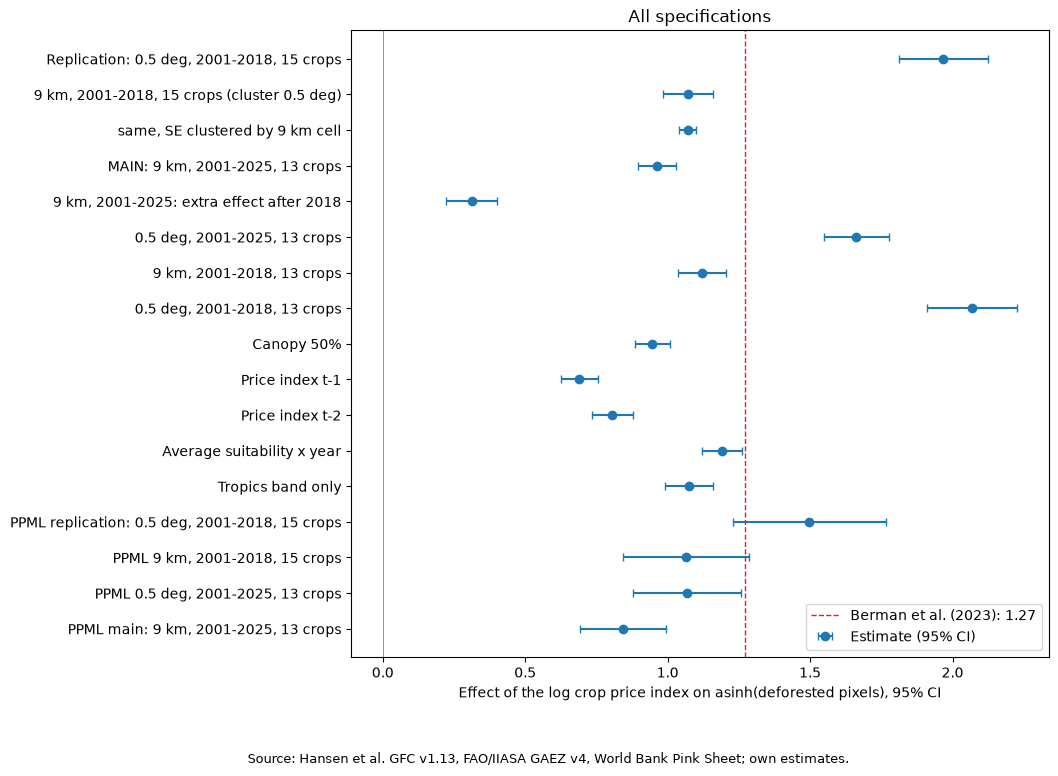

In [16]:
fig, ax = plt.subplots(figsize=(9, 0.42 * len(summary) + 1))
y = np.arange(len(summary))[::-1]
ax.errorbar(summary.Estimate, y, xerr=1.96 * summary["Std. Error"], fmt="o", capsize=3, label="Estimate (95% CI)")
ax.axvline(0, color="grey", lw=0.6)
ax.axvline(BERMAN_BETA, color="tab:red", ls="--", lw=1, label="Berman et al. (2023): 1.27")
ax.set_yticks(y)
ax.set_yticklabels(summary.index)
ax.set_xlabel("Effect of the log crop price index on asinh(deforested pixels), 95% CI")
ax.set_title("All specifications")
ax.legend(loc="lower right")
fig.text(0.01, -0.02, f"Source: {SRC_FOREST}, {SRC_GAEZ}, {SRC_PRICE}; own estimates.", fontsize=9)
plt.show()

### A.5 Beef: all estimates

Notebook 5. Cell level: 9 km cells, 2001-2025, cell and country x year fixed effects, control average suitability x year; SE clustered by country. Country level: 62 countries, 2001-2023, country and year fixed effects, outcome asinh of deforestation attributed to cattle (or to crops, placebo) in DeDuCE.

In [17]:
beef_all = pd.read_csv(RES + "beef_summary.csv")
beef_all[beef_all.term != "lnP"].round(3).reset_index(drop=True)

,level,model,term,Estimate,SE,N
0,9 km cells,1 Annual beef price,beef,-0.256,0.063,11354300
1,9 km cells,2 3-year moving average,beef_ma3,-0.273,0.072,11354300
2,9 km cells,3 5-year moving average,beef_ma5,-0.257,0.064,11354300
3,9 km cells,4 + forest 2000 x year,beef,-0.211,0.058,11354300
4,9 km cells,5 + cattle x trend,beef,-0.032,0.114,11354300
5,9 km cells,6 + cattle x trend + forest 2000 x year,beef,-0.012,0.112,11354300
6,9 km cells,7 Beef price without its trend,beef_detr,-0.029,0.113,11354300
7,9 km cells,8 By region,beef_LA,-0.351,0.051,11354300
8,9 km cells,8 By region,beef_AF,-0.194,0.168,11354300
9,9 km cells,8 By region,beef_AP,-0.103,0.082,11354300


### A.6 Use of AI tools

> **To write (Andrew):** as required by the course: say which AI tools you used and for what (coding help, debugging,
> checking numbers), and that all text is written by the team. Cite them like a reference.

### A.7 Reproducibility
Notebook 3 builds the price index; notebook 4 runs all models (by default it reads the 9 km results from
`data/processed/results/`; set `RECOMPUTE = True` to rerun them, about 15 minutes and 10 GB of RAM).
Notebook 5 runs the beef models (same `RECOMPUTE` switch, about 4 minutes and 10 GB of RAM).
Heavy preprocessing (Hansen tiles, WDPA polygons, Berman et al.'s files, FAOSTAT production and trade, AGLW cattle map) is in `scripts/`.

**References.** Berman, N., Couttenier, M., Leblois, A. and Soubeyran, R. (2023), Crop prices and deforestation
in the tropics, *Journal of Environmental Economics and Management*. Adao, R., Kolesar, M. and Morales, E.
(2019), Shift-share designs: theory and inference, *Quarterly Journal of Economics*. Hansen, M. et al. (2013),
High-resolution global maps of 21st-century forest cover change, *Science*. Assuncao, J., Gandour, C. and
Rocha, R. (2015), Deforestation slowdown in the Brazilian Amazon: prices or policies?, *Environment and
Development Economics*. Harding, T., Herzberg, J. and Kuralbayeva, K. (2021), Commodity prices and robust
environmental regulation: evidence from deforestation in Brazil, *Journal of Environmental Economics and
Management*. Singh, C. and Persson, U. M. (2026), DeDuCE: deforestation attributed to commodities. Du, Z. et al. (2025), Annual global gridded livestock mapping from 1961 to 2021, *Earth System Science Data* 17, 5543-5556.